In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline 

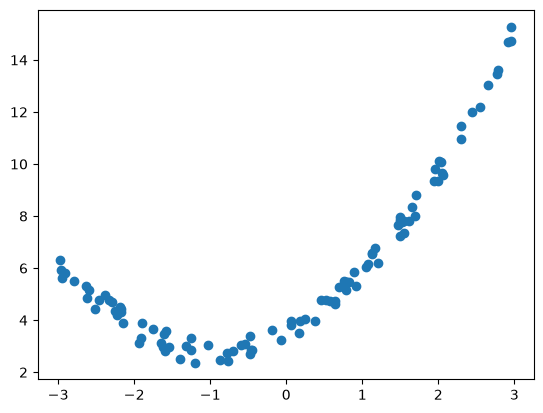

In [3]:
X =  6*np.random.rand(100,1) -3
y= 0.8 * X**2 + 1.5*X +3 + np.random.rand(100,1)
plt.scatter(X,y)

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=23)
print(X_train.shape, X_test.shape)


(80, 1) (20, 1)


In [8]:
from sklearn.linear_model import LinearRegression
regression_1 = LinearRegression()

In [10]:
regression_1.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1.35]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.97]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[15.56]


In [11]:
from sklearn.metrics import r2_score
score = r2_score(y_test,regression_1.predict(X_test))
print(score)

0.5410606660118282


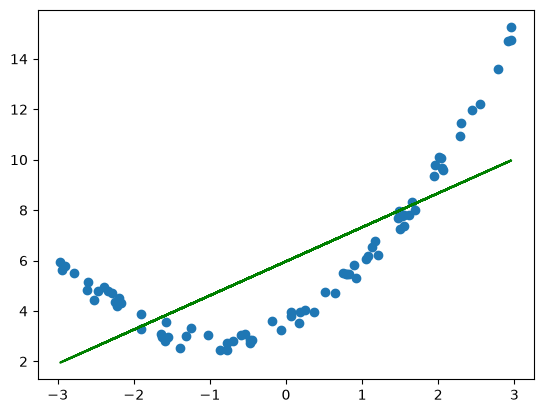

In [15]:
plt.plot(X_train,regression_1.predict(X_train),color="g")
plt.scatter(X_train,y_train)

In [13]:
from sklearn.preprocessing import PolynomialFeatures


In [16]:
poly = PolynomialFeatures(degree=2, include_bias=True)
X_train_poly= poly.fit_transform(X_train)

X_test_poly = poly.transform(X_test)

In [17]:
X_train_poly

array([[ 1.00000000e+00, -2.18879693e+00,  4.79083201e+00],
       [ 1.00000000e+00,  2.04870490e+00,  4.19719175e+00],
       [ 1.00000000e+00,  2.05884347e+00,  4.23883644e+00],
       [ 1.00000000e+00,  2.44388634e+00,  5.97258045e+00],
       [ 1.00000000e+00,  2.29221836e+00,  5.25426499e+00],
       [ 1.00000000e+00,  1.52246294e+00,  2.31789339e+00],
       [ 1.00000000e+00, -2.61652525e+00,  6.84620440e+00],
       [ 1.00000000e+00, -1.87267816e-01,  3.50692350e-02],
       [ 1.00000000e+00, -1.64674404e+00,  2.71176593e+00],
       [ 1.00000000e+00, -1.62283877e+00,  2.63360566e+00],
       [ 1.00000000e+00,  1.54477403e+00,  2.38632681e+00],
       [ 1.00000000e+00, -7.74844684e-01,  6.00384285e-01],
       [ 1.00000000e+00, -2.90317059e+00,  8.42839950e+00],
       [ 1.00000000e+00, -7.70242927e-01,  5.93274167e-01],
       [ 1.00000000e+00, -4.78533661e-01,  2.28994464e-01],
       [ 1.00000000e+00, -1.31410818e+00,  1.72688030e+00],
       [ 1.00000000e+00,  1.08046058e+00

In [18]:
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score= r2_score(y_test,y_pred)
score

0.9898747558216757

In [19]:
regression.coef_

array([[0.        , 1.49634262, 0.78950586]])

In [20]:
print(regression.intercept_)

[3.57419713]


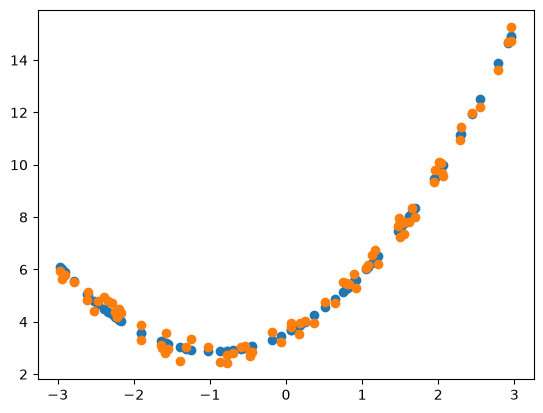

In [22]:
plt.scatter(X_train,regression.predict(X_train_poly))
plt.scatter(X_train,y_train)

In [26]:
from sklearn.pipeline import Pipeline


In [27]:
def poly_regression(degree):
    X_new = np.linspace(-3, 3, 200).reshape(200, 1)
    
    poly_features=PolynomialFeatures(degree=degree,include_bias=True)
    lin_reg=LinearRegression()
    poly_regression=Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
    ])
    poly_regression.fit(X_train,y_train) ## ploynomial and fit of linear reression
    y_pred_new=poly_regression.predict(X_new)
    #plotting prediction line
    plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)
    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-4,4, 0, 10])
    plt.show()

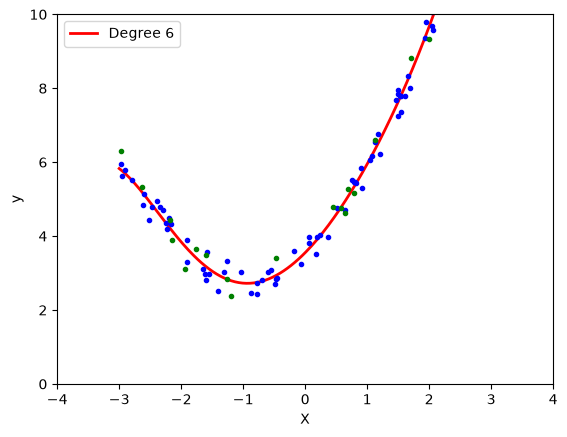

In [31]:
poly_regression(6)